In [19]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA = '/content/drive/MyDrive/NYPA PowerHack/data'
print(os.listdir(f'{DATA}/clean'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/NYPA PowerHack/data/clean'

In [ ]:
import os
import pandas as pd

DATA  = '/content/drive/MyDrive/NYPA PowerHack/data'
CLEAN = f'{DATA}/clean'

monthly = pd.read_csv(f'{CLEAN}/monthly_clean.csv', parse_dates=['date'])
daily   = pd.read_csv(f'{CLEAN}/daily_clean.csv',   parse_dates=['date'])
hourly  = pd.read_csv(f'{CLEAN}/hourly_clean.csv')
yearly  = pd.read_csv(f'{CLEAN}/yearly_shares.csv')
ef  = pd.read_csv(f'{CLEAN}/emissions_factors_clean.csv')

fuels       = ['natural_gas','dual_fuel','nuclear','hydro','wind','other_renewables','other_fossil']
mwh_cols    = [f + '_mwh' for f in fuels]
mw_cols     = [f + '_avg_mw' for f in fuels]
share_cols  = [f + '_share_pct' for f in fuels]

for name, df in [('monthly', monthly), ('daily', daily), ('hourly', hourly), ('yearly', yearly)]:
    print(f'{name:8s}', df.shape, '| missing:', int(df.isna().sum().sum()))

monthly.head()

monthly  (36, 26) | missing: 0
daily    (1096, 26) | missing: 0
hourly   (864, 24) | missing: 0
yearly   (3, 18) | missing: 0


,date,year,month,month_name,season,natural_gas_mwh,dual_fuel_mwh,nuclear_mwh,hydro_mwh,wind_mwh,...,zero_carbon_mwh,natural_gas_share_pct,dual_fuel_share_pct,nuclear_share_pct,hydro_share_pct,wind_share_pct,other_renewables_share_pct,other_fossil_share_pct,fossil_share_pct,zero_carbon_share_pct
0,2023-01-01,2023,1,Jan,Winter,2647071,2230614,2471425,2515014,317117,...,5482040,25.54,21.52,23.84,24.26,3.06,1.72,0.06,47.12,52.88
1,2023-02-01,2023,2,Feb,Winter,1965276,2518621,2187373,2166940,520180,...,5010837,20.66,26.47,22.99,22.77,5.47,1.43,0.21,47.34,52.66
2,2023-03-01,2023,3,Mar,Spring,1829051,2362288,2143697,2349213,489949,...,5145508,19.57,25.27,22.93,25.13,5.24,1.74,0.12,44.96,55.04
3,2023-04-01,2023,4,Apr,Spring,1794058,2063199,1772552,2231050,447304,...,4598750,21.21,24.39,20.95,26.37,5.29,1.75,0.04,45.64,54.36
4,2023-05-01,2023,5,May,Spring,1914483,2250960,2458572,2300320,330457,...,5293990,20.23,23.79,25.99,24.31,3.49,2.16,0.02,44.05,55.95


In [ ]:
import matplotlib.pyplot as plt

# 1) Check: total equals the sum of the 7 fuels, in every month
gap = (monthly[mwh_cols].sum(axis=1) - monthly['total_mwh']).abs().max()
print('Max gap between sum of fuels and total_mwh:', gap, 'MWh (should be 0)')

# 2) Yearly share = yearly fuel MWh / yearly total MWh
#    (sum MWh first, don't average the monthly percentages)
yr = monthly.groupby('year')[mwh_cols + ['total_mwh']].sum()
shares = yr[mwh_cols].div(yr['total_mwh'], axis=0) * 100
shares.columns = fuels

print('Shares sum to:', shares.sum(axis=1).round(6).tolist())

# 3) Fossil vs zero-carbon
fossil = ['natural_gas', 'dual_fuel', 'other_fossil']
shares['fossil']      = shares[fossil].sum(axis=1)
shares['zero_carbon'] = 100 - shares['fossil']
shares['total_TWh']   = yr['total_mwh'] / 1e6

display(shares.round(2).T)

# 4) Change in percentage points, first year to last year
print((shares.drop(columns='total_TWh').iloc[-1] - shares.drop(columns='total_TWh').iloc[0]).round(2))

# 5) Cross-check against your yearly_shares.csv
display(yearly.head())

Max gap between sum of fuels and total_mwh: 0 MWh (should be 0)
Shares sum to: [100.0, 100.0, 100.0]


year,2023,2024,2025
natural_gas,23.28,24.70,25.09
dual_fuel,27.26,27.01,27.54
nuclear,22.06,20.76,21.39
hydro,21.75,20.64,18.21
wind,3.75,4.68,5.35
other_renewables,1.78,2.10,2.27
other_fossil,0.14,0.11,0.15
fossil,50.67,51.82,52.78
zero_carbon,49.33,48.18,47.22
total_TWh,125.00,130.72,133.16


natural_gas         1.81
dual_fuel           0.28
nuclear            -0.66
hydro              -3.54
wind                1.60
other_renewables    0.49
other_fossil        0.02
fossil              2.11
zero_carbon        -2.11
dtype: float64


,year,natural_gas_mwh,dual_fuel_mwh,nuclear_mwh,hydro_mwh,wind_mwh,other_renewables_mwh,other_fossil_mwh,total_mwh,natural_gas_share_pct,dual_fuel_share_pct,nuclear_share_pct,hydro_share_pct,wind_share_pct,other_renewables_share_pct,other_fossil_share_pct,fossil_share_pct,zero_carbon_share_pct
0,2023,29095357,34069200,27568511,27184674,4684018,2225874,170965,124998599,23.28,27.26,22.06,21.75,3.75,1.78,0.14,50.67,49.33
1,2024,32286574,35314488,27136684,26976070,6119949,2745399,144774,130723938,24.70,27.01,20.76,20.64,4.68,2.10,0.11,51.82,48.18
2,2025,33407356,36669486,28485719,24248709,7122305,3022122,203633,133159330,25.09,27.54,21.39,18.21,5.35,2.27,0.15,52.78,47.22


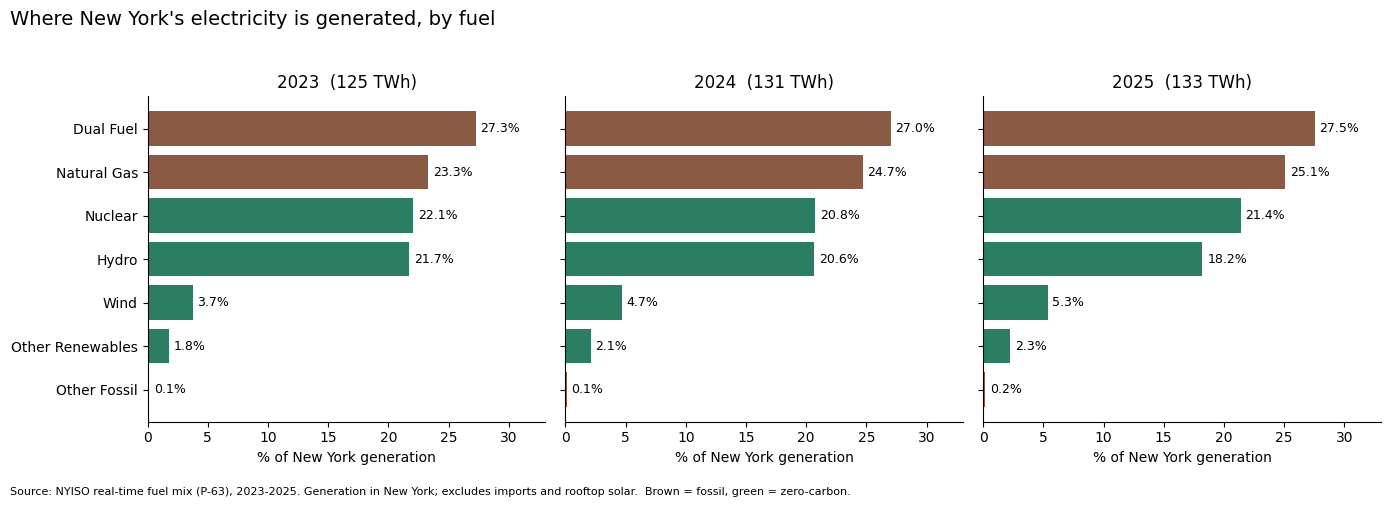

In [ ]:
labels = {'natural_gas':'Natural Gas','dual_fuel':'Dual Fuel','nuclear':'Nuclear',
          'hydro':'Hydro','wind':'Wind','other_renewables':'Other Renewables',
          'other_fossil':'Other Fossil'}
fossil_color, clean_color = '#8a5a44', '#2a7f62'

years = list(shares.index)
order = shares.loc[years[-1], fuels].sort_values().index   # same order in every panel

fig, axes = plt.subplots(1, len(years), figsize=(14, 5), sharex=True, sharey=True)
for ax, y in zip(axes, years):
    vals = shares.loc[y, order]
    bars = ax.barh([labels[f] for f in order], vals,
                   color=[fossil_color if f in fossil else clean_color for f in order])
    for b, v in zip(bars, vals):
        ax.text(v + 0.4, b.get_y() + b.get_height()/2, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_title(f"{y}  ({shares.loc[y, 'total_TWh']:.0f} TWh)")
    ax.set_xlim(0, shares[fuels].to_numpy().max() * 1.2)
    ax.set_xlabel('% of New York generation')
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle("Where New York's electricity is generated, by fuel", fontsize=14, x=0.01, ha='left')
fig.text(0.01, 0.01, 'Source: NYISO real-time fuel mix (P-63), 2023-2025. Generation in New York; '
         'excludes imports and rooftop solar.  Brown = fossil, green = zero-carbon.', fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(f'{DATA}/energy_mix_by_year.png', dpi=200)
plt.show()